# Entrenamiento de CNN ResNet-18 con Transfer Learning
## Objetivos

- Construir un modelo baseline de clasificación mediante transfer learning con ResNet18 preentrenada.
- Entrenar inicialmente solo la capa clasificadora y descongelar `layer4` en `UNFREEZE_EPOCH` con una tasa de aprendizaje menor.
- Aplicar transformaciones y aumentación de datos al conjunto de entrenamiento.
- Entrenar y validar el modelo registrando loss y accuracy por época.
- Detener el entrenamiento si val_loss no mejora suficientemente durante la paciencia configurada.
- Evaluar el modelo de la mejor época de validación sobre el conjunto de prueba.
- Analizar los resultados mediante accuracy, precision, recall, F1-score, reporte de clasificación y matriz de confusión normalizada.
- Guardar los pesos restaurados de la mejor época de validación (o los finales si se desactiva la parada anticipada).

In [1]:
# Importaciones

import matplotlib.pyplot as plt

from vasijas.paths import ProjectPaths, ruta_relativa
from vasijas.config import load_config
from vasijas.metadata import cargar_metadata
from vasijas.entrenamiento_cnn import (
    ConfiguracionTransformacionesImagen,
    calcular_resultado_clasificacion,
    crear_criterio_entropia_cruzada,
    crear_dataloaders_imagen_desde_metadata,
    crear_modelo_transfer_learning,
    crear_optimizador_adam,
    describir_dispositivo,
    describir_metricas_epoch,
    entrenar_modelo,
    graficar_historial_entrenamiento,
    graficar_lote_imagenes,
    graficar_matriz_confusion,
    guardar_pesos_modelo,
    seleccionar_dispositivo_procesamiento,
    validar_modelo,
)

In [2]:
# Configuracion general
CONFIG = load_config()
PATHS = ProjectPaths.from_root(CONFIG.project_root)

## Dispositivo para procesamiento

In [3]:
DEVICE = seleccionar_dispositivo_procesamiento()
print(describir_dispositivo(DEVICE))

Dispositivo utilizado para procesamiento: CUDA - NVIDIA GeForce GTX 1650


In [4]:
# Parámetros

# Modelo
MODEL_NAME = "resnet18"
RUN_NAME = "default"

# Entrenamiento
BATCH_SIZE = 16
NUM_WORKERS = 8  # Usar 0 para desactivar la carga paralela.
EPOCHS = 30  # Máximo de épocas.
EARLY_STOPPING_PATIENCE = 15  # None desactiva la parada anticipada.
EARLY_STOPPING_MIN_DELTA = 0.001
USE_CLASS_WEIGHTS = False
USE_AMP = True
USE_CHANNELS_LAST = True
LR = 1e-3

UNFREEZE_EPOCH = None
BACKBONE_LR_FACTOR = 0.1

# Preprocesamiento
IMG_SIZE = 224
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Aumentación de datos
FLIP_PROBABILITY = 0.5
SCALING_FACTOR_INTERVAL = (0.7, 1.0)
ROTATION_DEGREES = 15
PIXEL_FILL = (255, 255, 255)

# Datos de entrada y división persistida
DATASET_NAME = "completos"

In [5]:
# Parameters
DATASET_NAME = "unificado"
MODEL_NAME = "resnet18"
RUN_NAME = "bs16_lr1e-3_weighted_unfreeze"
BATCH_SIZE = 16
EPOCHS = 300
EARLY_STOPPING_PATIENCE = 30
EARLY_STOPPING_MIN_DELTA = 0.001
LR = 0.001
UNFREEZE_EPOCH = 10
BACKBONE_LR_FACTOR = 0.1
USE_CLASS_WEIGHTS = True
FLIP_PROBABILITY = 0.5
ROTATION_DEGREES = [-15, 15]
SCALING_FACTOR_INTERVAL = [0.8, 1.0]
IMG_SIZE = 224
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]
PIXEL_FILL = [255, 255, 255]
NUM_WORKERS = 8
USE_AMP = True
USE_CHANNELS_LAST = True


## División de datos

La pertenencia de cada imagen a `train`, `val` o `test` se lee de la metadata generada por el notebook de división. La relación se realiza mediante `ruta_relativa`; por tanto, el split no se recalcula aunque cambien la semilla o los parámetros del entrenamiento.

In [6]:
# Metadata, transformaciones y dataloaders
# Resolver después de la inyección de parámetros de Papermill.
rutas_dataset = {
    "completos": PATHS.DATA_CUADRADOS_DIVIDIDO,
    "unificado": PATHS.DATA_UNIFICADO_DIVIDIDO,
}
if DATASET_NAME not in rutas_dataset:
    raise ValueError(
        f"Dataset desconocido: {DATASET_NAME!r}. Opciones: {', '.join(rutas_dataset)}"
    )
DATA_DIR = rutas_dataset[DATASET_NAME]
if not DATA_DIR.is_dir():
    raise FileNotFoundError(f"No existe el directorio del dataset: {DATA_DIR}")
if not (DATA_DIR / "metadata.csv").is_file():
    raise FileNotFoundError(
        f"No existe la metadata de split: {DATA_DIR / 'metadata.csv'}"
    )
print(f"Dataset seleccionado: {DATASET_NAME}")
print(f"Directorio de datos: {DATA_DIR}")
metadata_split = cargar_metadata(DATA_DIR)

config_transformaciones = ConfiguracionTransformacionesImagen(
    tamano_imagen=IMG_SIZE,
    probabilidad_flip=FLIP_PROBABILITY,
    intervalo_escalado=SCALING_FACTOR_INTERVAL,
    grados_rotacion=ROTATION_DEGREES,
    relleno_pixeles=PIXEL_FILL,
    media_normalizacion=IMAGENET_MEAN,
    desvio_normalizacion=IMAGENET_STD,
)

dataloaders = crear_dataloaders_imagen_desde_metadata(
    data_dir=DATA_DIR,
    metadata_split=metadata_split,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    configuracion_transformaciones=config_transformaciones,
)

train_loader = dataloaders.train
val_loader = dataloaders.val
test_loader = dataloaders.test
class_names = dataloaders.class_names
NUM_CLASSES = dataloaders.num_classes

print(f"Metadata de split: {ruta_relativa(DATA_DIR / 'metadata.csv')}")
print("Clases:", *class_names)
print(
    f"Split persistido -> train: {len(train_loader.dataset)}, "
    f"val: {len(val_loader.dataset)}, "
    f"test: {len(test_loader.dataset)}"
)

Dataset seleccionado: unificado
Directorio de datos: /home/rafael/Dev/vasijas/data/12.unificado_divididos_en_train_val_y_test


Metadata de split: data/12.unificado_divididos_en_train_val_y_test/metadata.csv
Clases: clase01 clase02 clase03 clase05 clase06 clase07 clase08 clase09 clase10 clase11
Split persistido -> train: 14231, val: 3059, test: 3059


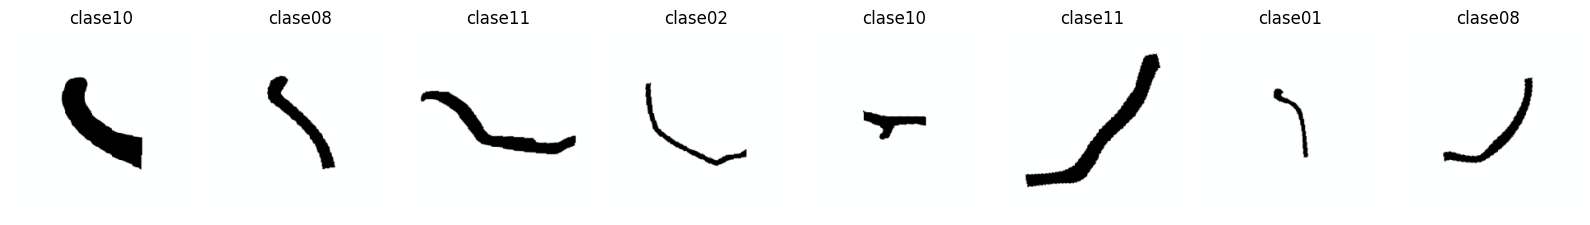

In [7]:
# Visualización rápida (sanity check)
graficar_lote_imagenes(loader=train_loader, nombres_clases=class_names, cantidad=8)
plt.show()

model = crear_modelo_transfer_learning(
    nombre_modelo=MODEL_NAME,
    num_classes=NUM_CLASSES,
    dispositivo=DEVICE,
)

In [8]:
# Criterio y optimizador
criterion = crear_criterio_entropia_cruzada(
    usar_pesos_clases=USE_CLASS_WEIGHTS,
    train_loader=train_loader,
    num_classes=NUM_CLASSES,
    dispositivo=DEVICE,
)
optimizer = crear_optimizador_adam(model, learning_rate=LR)

Conteo train por clase: [342, 608, 950, 741, 684, 646, 3724, 266, 4712, 1558]
Pesos de clase: [4.161, 2.341, 1.498, 1.921, 2.081, 2.203, 0.382, 5.35, 0.302, 0.913]


In [9]:
# Entrenamiento y validación
backbone_lr = LR * BACKBONE_LR_FACTOR

historial = entrenar_modelo(
    modelo=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterio=criterion,
    optimizador=optimizer,
    dispositivo=DEVICE,
    usar_amp=USE_AMP,
    usar_channels_last=USE_CHANNELS_LAST,
    epochs=EPOCHS,
    early_stopping_patience=EARLY_STOPPING_PATIENCE,
    early_stopping_min_delta=EARLY_STOPPING_MIN_DELTA,
    model_name=MODEL_NAME,
    unfreeze_epoch=UNFREEZE_EPOCH,
    backbone_lr=backbone_lr,
    al_finalizar_epoch=lambda metrica: print(
        describir_metricas_epoch(metrica, total_epochs=EPOCHS)
    ),
)

Epoch 1/300
Train Loss: 1.8285 | Train Acc: 0.4143 | Val Loss: 1.6300 | Val Acc: 0.4413
Tiempo de epoch: 0:01:27.819557 



Epoch 2/300
Train Loss: 1.5550 | Train Acc: 0.4882 | Val Loss: 1.7207 | Val Acc: 0.2870
Tiempo de epoch: 0:01:26.889098 



Epoch 3/300
Train Loss: 1.4744 | Train Acc: 0.5123 | Val Loss: 1.5350 | Val Acc: 0.4439
Tiempo de epoch: 0:01:23.738022 



Epoch 4/300
Train Loss: 1.4637 | Train Acc: 0.5125 | Val Loss: 1.4258 | Val Acc: 0.4652
Tiempo de epoch: 0:01:23.677121 



Epoch 5/300
Train Loss: 1.4269 | Train Acc: 0.5158 | Val Loss: 1.3224 | Val Acc: 0.5286
Tiempo de epoch: 0:01:24.093011 



Epoch 6/300
Train Loss: 1.4061 | Train Acc: 0.5215 | Val Loss: 1.5324 | Val Acc: 0.4178
Tiempo de epoch: 0:01:24.508159 



... (85 outputs left out)

Epoch 92/300
Train Loss: 0.2570 | Train Acc: 0.8680 | Val Loss: 0.8157 | Val Acc: 0.7692
Tiempo de epoch: 0:01:56.244771 



Epoch 93/300
Train Loss: 0.2637 | Train Acc: 0.8664 | Val Loss: 0.7533 | Val Acc: 0.7339
Tiempo de epoch: 0:01:56.139978 



Epoch 94/300
Train Loss: 0.2744 | Train Acc: 0.8668 | Val Loss: 0.7756 | Val Acc: 0.7627
Tiempo de epoch: 0:01:56.219691 



Epoch 95/300
Train Loss: 0.2631 | Train Acc: 0.8678 | Val Loss: 0.7098 | Val Acc: 0.7774
Tiempo de epoch: 0:01:56.132582 

Parada anticipada en epoch 95: 30 épocas sin mejora suficiente de val_loss.
Se restauran los pesos de epoch 65 (val_loss=0.5895).
Tiempo total de entrenamiento: 2:59:52.955694


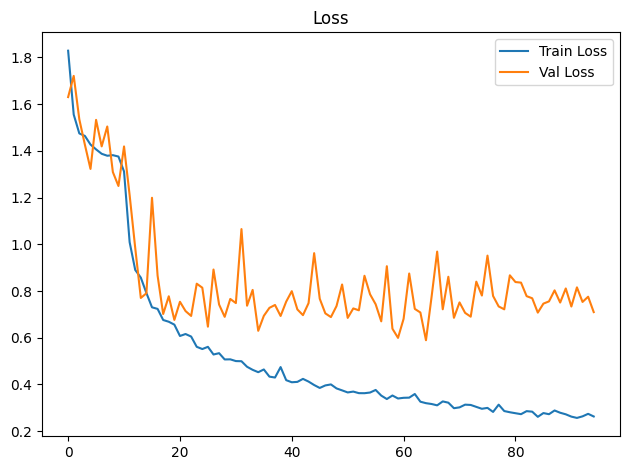

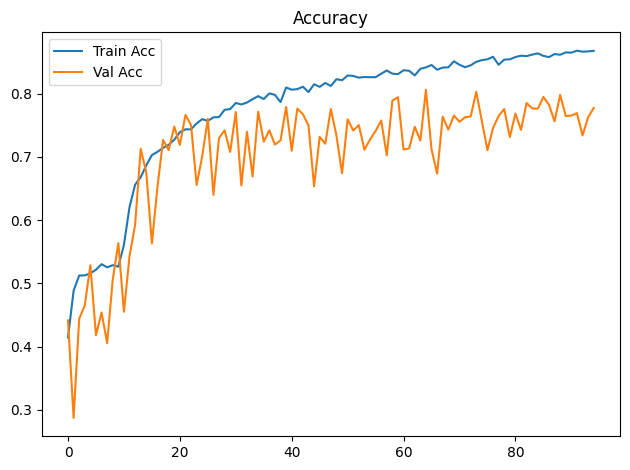

In [10]:
# Curvas de entrenamiento
graficar_historial_entrenamiento(historial)
plt.show()

Test Acc: 0.7774
              precision    recall  f1-score   support

     clase01       0.84      0.84      0.84        76
     clase02       0.41      0.71      0.52       133
     clase03       0.76      0.69      0.72       209
     clase05       0.79      0.86      0.82       152
     clase06       0.65      0.52      0.58       152
     clase07       0.81      0.91      0.86       133
     clase08       0.85      0.75      0.80       798
     clase09       0.39      0.53      0.45        57
     clase10       0.87      0.90      0.88      1007
     clase11       0.69      0.61      0.65       342

    accuracy                           0.78      3059
   macro avg       0.71      0.73      0.71      3059
weighted avg       0.79      0.78      0.78      3059



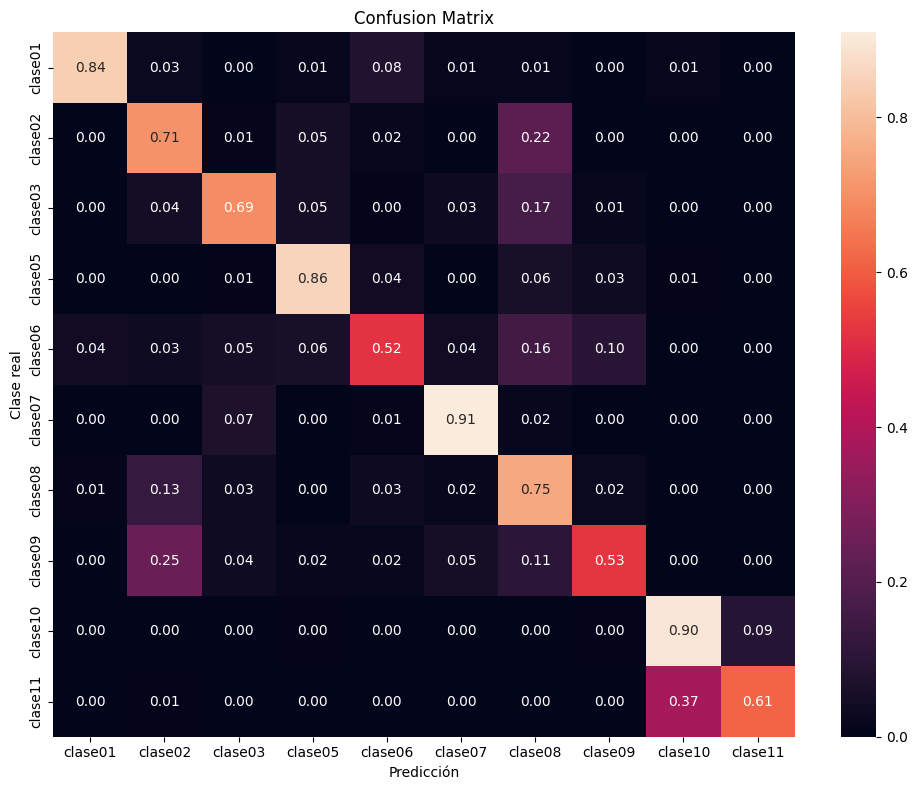

In [11]:
# Evaluación final
resultado_test = validar_modelo(
    modelo=model,
    loader=test_loader,
    criterio=criterion,
    dispositivo=DEVICE,
    usar_amp=USE_AMP,
    usar_channels_last=USE_CHANNELS_LAST,
)
resultado_clasificacion = calcular_resultado_clasificacion(
    resultado=resultado_test,
    nombres_clases=class_names,
)

print(f"Test Acc: {resultado_test.accuracy:.4f}")
print(resultado_clasificacion.reporte)

graficar_matriz_confusion(
    matriz=resultado_clasificacion.matriz_confusion,
    nombres_clases=class_names,
)
plt.show()

In [12]:
# Guardado del modelo
ruta_modelo = guardar_pesos_modelo(
    modelo=model,
    ruta_destino=PATHS.OUTPUT_MODELS / f"model_{MODEL_NAME}_{DATASET_NAME}_{RUN_NAME}.pth",
)
print(f"Modelo guardado en: {ruta_relativa(ruta_modelo)}")

Modelo guardado en: output/models/model_resnet18_unificado_bs16_lr1e-3_weighted_unfreeze.pth
